# Olist Brazilian E-Commerce Analysis

## 1. Problem Statement & Objectives
Using the Olist e-commerce database, our objective is to analyze transaction patterns, logistics efficiency, and customer behavior to optimize business operations.

Specifically, we aim to solve:
- **Predicting/Analyzing Order Delivery Delays:** Identifying why orders get delayed, measuring the actual versus estimated delivery times, and finding key factors (distance, product weight, seller locations) contributing to bottlenecks.
- **Customer Satisfaction & Review Behavior:** Understanding the impact of late deliveries and price structures on customer review scores.

### 2. Our Approach
1. **Data Integration:** Load and merge the various relational datasets (Orders, Items, Customers, Sellers, Geolocation, and Reviews).
2. **Exploratory Data Analysis (EDA):** Perform deep-dive statistical analysis and visualize the distributions, correlations, and geospatial trends.
3. **Feature Engineering:** Calculate actual delivery speed, geographical distances using latitude/longitude, and extract temporal patterns.
4. **Modeling:** Train models to predict late deliveries or low review scores.

### 3. Libraries Used
For our analysis and visualizations, we will utilize:
- **Data Manipulation:** `pandas`, `numpy`
- **Static Visualizations:** `matplotlib`, `seaborn`
- **Interactive Visualizations:** `plotly`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style='whitegrid')

# Load all datasets
orders = pd.read_csv('/content/olist_orders_dataset.csv')
items = pd.read_csv('/content/olist_order_items_dataset.csv')
payments = pd.read_csv('/content/olist_order_payments_dataset.csv')
customers = pd.read_csv('/content/olist_customers_dataset.csv')
sellers = pd.read_csv('/content/olist_sellers_dataset.csv')
products = pd.read_csv('/content/olist_products_dataset.csv')
reviews = pd.read_csv('/content/olist_order_reviews_dataset.csv')
geolocation = pd.read_csv('/content/olist_geolocation_dataset.csv')
translation = pd.read_csv('/content/product_category_name_translation.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [2]:
# Preview the shape of each dataset to verify
for name, df in zip(
    ['Orders', 'Items', 'Payments', 'Customers', 'Sellers', 'Products', 'Reviews', 'Geolocation'],
    [orders, items, payments, customers, sellers, products, reviews, geolocation]
):
    print(f"{name:12} : {df.shape[0]:,} rows, {df.shape[1]} columns")

Orders       : 99,441 rows, 8 columns
Items        : 112,650 rows, 7 columns
Payments     : 103,886 rows, 5 columns
Customers    : 99,441 rows, 5 columns
Sellers      : 3,095 rows, 4 columns
Products     : 32,951 rows, 9 columns
Reviews      : 99,224 rows, 7 columns
Geolocation  : 1,000,163 rows, 5 columns


## 1. Load, Merge, and Inspect
First, we merge the core datasets (`orders`, `items`, `customers`, and `translation`) so we can have a unified view of the orders, logistics, and product categories translated to English.

In [3]:
# Merge orders with items to get products involved, and customers to get location
merged_df = orders.merge(items, on='order_id', how='inner')
merged_df = merged_df.merge(customers, on='customer_id', how='left')
merged_df = merged_df.merge(products, on='product_id', how='left')
merged_df = merged_df.merge(translation, on='product_category_name', how='left')

# Drop foreign category name and keep the English translation
if 'product_category_name_english' in merged_df.columns:
    merged_df['product_category'] = merged_df['product_category_name_english']
    merged_df.drop(columns=['product_category_name', 'product_category_name_english'], inplace=True, errors='ignore')

print(f"Unified Merged Dataset: {merged_df.shape[0]} rows, {merged_df.shape[1]} columns.")
display(merged_df.head(3))

Unified Merged Dataset: 112650 rows, 26 columns.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,customer_city,customer_state,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,...,sao paulo,SP,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,...,barreiras,BA,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,...,vianopolis,GO,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto


## 2. Data Cleaning
We identify missing values, ensure correct datetime types, handle duplicates, and define the targeted target variable: `is_delayed`.

In [4]:
# Check for missing values in critical columns
print("Missing values per column:\n", merged_df.isnull().sum())

# Convert datetime columns
datetime_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_cols:
    merged_df[col] = pd.to_datetime(merged_df[col])

# Handle duplicates
duplicates_count = merged_df.duplicated().sum()
print(f"\nNumber of duplicate rows found: {duplicates_count}")
if duplicates_count > 0:
    merged_df.drop_duplicates(inplace=True)

# Create our target feature: is_delayed (1 if delivered after estimate, 0 otherwise)
# For missing delivery dates, we ignore them for delivery performance tracking
valid_deliveries = merged_df.dropna(subset=['order_delivered_customer_date']).copy()
valid_deliveries['is_delayed'] = (valid_deliveries['order_delivered_customer_date'] > valid_deliveries['order_estimated_delivery_date']).astype(int)

print(f"Dataset with valid delivery status records: {valid_deliveries.shape[0]} rows.")

Missing values per column:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  15
order_delivered_carrier_date     1194
order_delivered_customer_date    2454
order_estimated_delivery_date       0
order_item_id                       0
product_id                          0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
product_name_lenght              1603
product_description_lenght       1603
product_photos_qty               1603
product_weight_g                   18
product_length_cm                  18
product_height_cm                  18
product_width_cm                   18
product_category      

## 3. Group By and Aggregations
We aggregate statistics by customer state to see where delays and higher shipping costs are concentrated.

In [5]:
# Aggregate by state
state_agg = valid_deliveries.groupby('customer_state').agg(
    total_orders=('order_id', 'nunique'),
    avg_freight_value=('freight_value', 'mean'),
    avg_price=('price', 'mean'),
    delay_rate=('is_delayed', 'mean')
).reset_index().sort_values(by='total_orders', ascending=False)

display(state_agg.head(10))

,customer_state,total_orders,avg_freight_value,avg_price,delay_rate
25,SP,40495,15.114994,109.094434,0.057684
18,RJ,12353,20.909784,124.418388,0.129719
10,MG,11355,20.625837,120.191362,0.054502
22,RS,5344,21.614270,118.819252,0.068808
17,PR,4923,20.471816,117.908216,0.047796
23,SC,3547,21.506628,123.754790,0.096144
4,BA,3256,26.487556,134.016872,0.136845
6,DF,2080,21.072161,125.901660,0.074310
7,ES,1995,22.028980,120.738629,0.122247
8,GO,1957,22.562868,124.214625,0.078612


## 4. Pivot Tables
We build a pivot table comparing the top 10 product categories against customer states to map out mean pricing patterns.

In [6]:
# Get top 10 product categories
top_categories = valid_deliveries['product_category'].value_counts().head(10).index.tolist()
filtered_categories_df = valid_deliveries[valid_deliveries['product_category'].isin(top_categories)]

# Create a pivot table of average prices across top product categories and customer states
pivot_prices = filtered_categories_df.pivot_table(
    values='price',
    index='product_category',
    columns='customer_state',
    aggfunc='mean'
).fillna(0)

display(pivot_prices.iloc[:, :10]) # Displaying first 10 states for cleaner visualization

customer_state,AC,AL,AM,AP,BA,CE,DF,ES,GO,MA
product_category,,,,,,,,,,
auto,135.245000,208.115455,120.650000,405.463333,187.823935,203.556897,162.816415,140.849643,115.400612,135.670769
bed_bath_table,141.925000,101.586316,85.150000,111.583333,98.226496,83.960370,78.386990,101.298879,96.474502,110.128611
computers_accessories,154.812500,195.015641,113.483750,256.253750,130.543320,132.781264,152.906667,96.161200,112.425447,181.385522
furniture_decor,109.703333,119.616333,53.820000,90.266667,93.607976,102.498072,79.608013,89.053241,97.821138,98.786000
garden_tools,314.500000,122.167692,396.176000,119.995000,135.449209,108.742545,154.119000,102.859118,128.491197,84.629130
health_beauty,198.082857,204.536452,138.801500,138.058000,146.926824,194.719136,122.077769,122.935583,123.221586,143.957727
housewares,128.265000,66.706667,102.172500,122.622500,107.701169,124.251071,83.937647,102.763036,114.211628,99.365000
sports_leisure,186.384444,115.555625,113.550000,116.098571,129.405804,113.854066,103.060917,116.105202,117.984969,129.674923
telephony,220.792000,164.228148,51.066667,76.195000,83.662033,75.136848,66.478462,78.714474,49.867917,77.766094


## 5. Visualizations (Static and Interactive)
Let's visualize the delay rates by state using Seaborn, and build an interactive timeline of sales volume using Plotly.

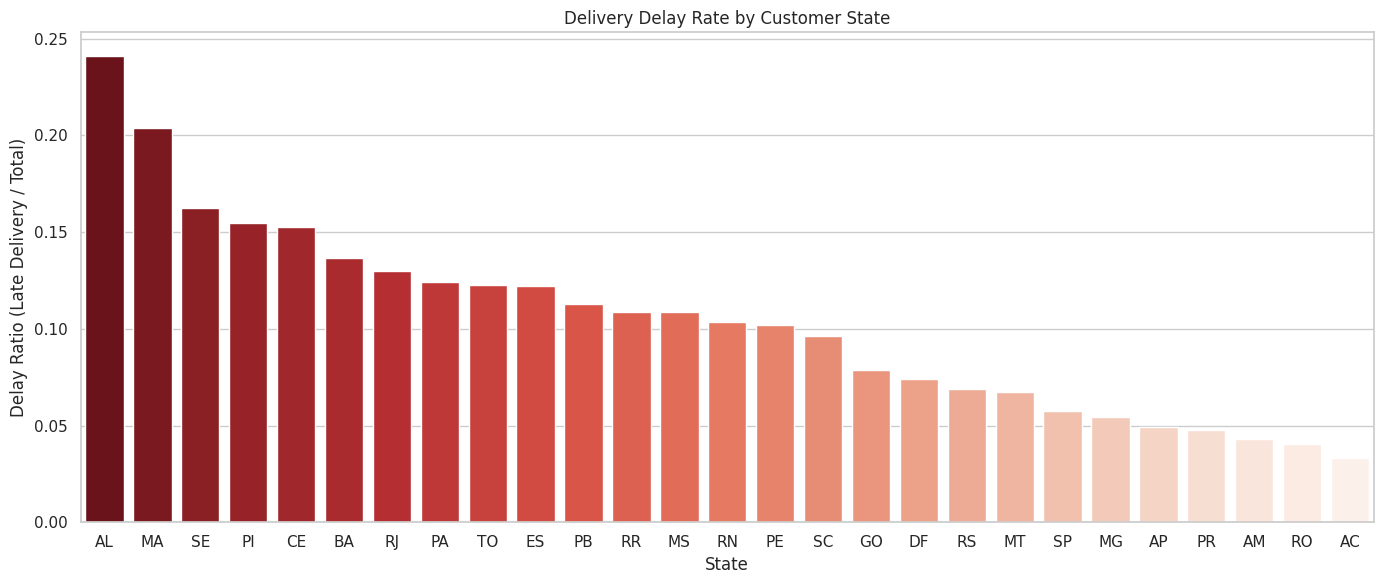

In [7]:
# Static Bar Plot: Delay rate by state
plt.figure(figsize=(14, 6))
sns.barplot(
    data=state_agg.sort_values(by='delay_rate', ascending=False),
    x='customer_state',
    y='delay_rate',
    hue='customer_state',
    palette='Reds_r',
    legend=False
)
plt.title('Delivery Delay Rate by Customer State')
plt.xlabel('State')
plt.ylabel('Delay Ratio (Late Delivery / Total)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# Interactive Plotly Timeline: Monthly Order Volume
valid_deliveries['year_month'] = valid_deliveries['order_purchase_timestamp'].dt.to_period('M').astype(str)
monthly_sales = valid_deliveries.groupby('year_month').size().reset_index(name='order_count')

fig = px.line(
    monthly_sales,
    x='year_month',
    y='order_count',
    title='Monthly Order Trends (Interactive)',
    labels={'year_month': 'Year-Month', 'order_count': 'Total Orders'},
    markers=True
)
fig.update_layout(xaxis_tickangle=-45)
fig.show()

## 6. Predictive Modeling: Forecasting Delivery Delays
We will now prepare a predictive classification model using Scikit-Learn. Our target is `is_delayed` (1 if late, 0 if on time).

### Steps:
1. **Feature Selection:** Use price, freight_value, product weight/dimensions, and customer state.
2. **Preprocessing:** Encode categorical states and scale numeric values.
3. **Train-Test Split:** Perform a balanced evaluations split.
4. **Baseline Model:** Train and evaluate a Random Forest classifier.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Prepare features
features = [
    'price', 'freight_value', 'product_weight_g',
    'product_length_cm', 'product_height_cm',
    'product_width_cm', 'customer_state'
]

# Drop rows with missing feature values to ensure a clean dataset for ML
ml_df = valid_deliveries.dropna(subset=features).copy()

X = ml_df[features]
y = ml_df['is_delayed']

# Train-test split (80/20 stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]:,} rows")
print(f"Testing set size: {X_test.shape[0]:,} rows")

Training set size: 88,142 rows
Testing set size: 22,036 rows


In [10]:
# Build preprocessing pipeline
numeric_features = ['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
categorical_features = ['customer_state']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Create full pipeline with a Random Forest baseline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))
])

# Train baseline model
model_pipeline.fit(X_train, y_train)

# Make predictions
y_pred = model_pipeline.predict(X_test)
y_probs = model_pipeline.predict_proba(X_test)[:, 1]

# Evaluate baseline performance
print("Classification Report:\n", classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_probs))

Classification Report:
               precision    recall  f1-score   support

           0       0.92      1.00      0.96     20293
           1       1.00      0.00      0.00      1743

    accuracy                           0.92     22036
   macro avg       0.96      0.50      0.48     22036
weighted avg       0.93      0.92      0.88     22036

ROC-AUC Score: 0.6608494929659151


## 7. Handling Class Imbalance & Feature Importance
Because only ~8% of the orders are delayed, our baseline model biased completely toward the majority class (on-time delivery).

### Optimization Strategy:
- Introduce `class_weight='balanced'` in our Random Forest Classifier to penalize minority class misclassifications.
- Evaluate the updated precision, recall, and ROC-AUC metrics.
- Extract and plot the feature importances to identify structural bottlenecks.

In [11]:
# Rebuild model pipeline with class balancing enabled
balanced_model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1))
])

# Fit the balanced model
balanced_model_pipeline.fit(X_train, y_train)

# Predict
y_pred_bal = balanced_model_pipeline.predict(X_test)
y_probs_bal = balanced_model_pipeline.predict_proba(X_test)[:, 1]

# Evaluate optimized performance
print("Balanced Model Classification Report:\n", classification_report(y_test, y_pred_bal))
print("Balanced Model ROC-AUC Score:", roc_auc_score(y_test, y_probs_bal))

Balanced Model Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.70      0.80     20293
           1       0.13      0.54      0.21      1743

    accuracy                           0.69     22036
   macro avg       0.54      0.62      0.51     22036
weighted avg       0.88      0.69      0.76     22036

Balanced Model ROC-AUC Score: 0.6604765147559001


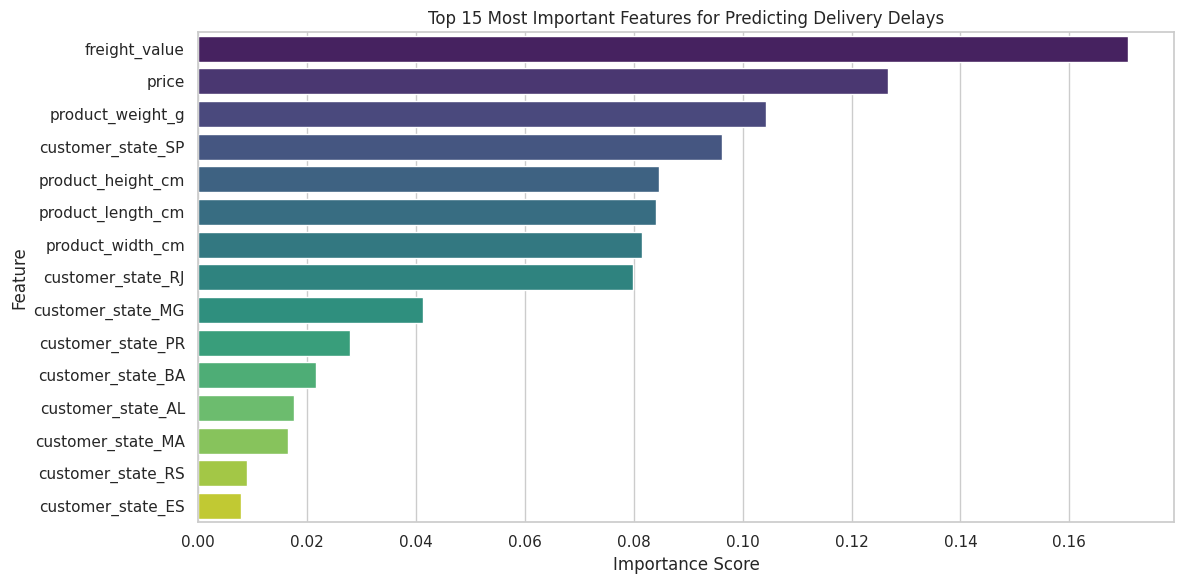

In [12]:
# Extract feature importances
classifier = balanced_model_pipeline.named_steps['classifier']
cat_encoder = balanced_model_pipeline.named_steps['preprocessor'].named_transformers_['cat']

# Combine numeric and encoded categorical feature names
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_features = numeric_features + encoded_cat_features

importances = classifier.feature_importances_
indices = np.argsort(importances)[::-1]

# Create a DataFrame for visual inspection
importance_df = pd.DataFrame({
    'Feature': [all_features[i] for i in indices],
    'Importance': importances[indices]
})

# Plot top 15 features
plt.figure(figsize=(12, 6))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 15 Most Important Features for Predicting Delivery Delays')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 8. Advanced EDA: Univariate, Bivariate, and Multivariate Analysis
We expand our EDA to uncover hidden distributions, relationships, and multi-variable correlations in our dataset.

### Analysis Structure:
1. **Univariate Analysis:** Inspecting the distribution of numerical features like `price` and `freight_value` using density plots.
2. **Bivariate Analysis:** Investigating the correlation of continuous variables and delivery delay status.
3. **Multivariate Analysis:** Analyzing correlation matrices and plotting interactive multidimensional relations using Plotly.

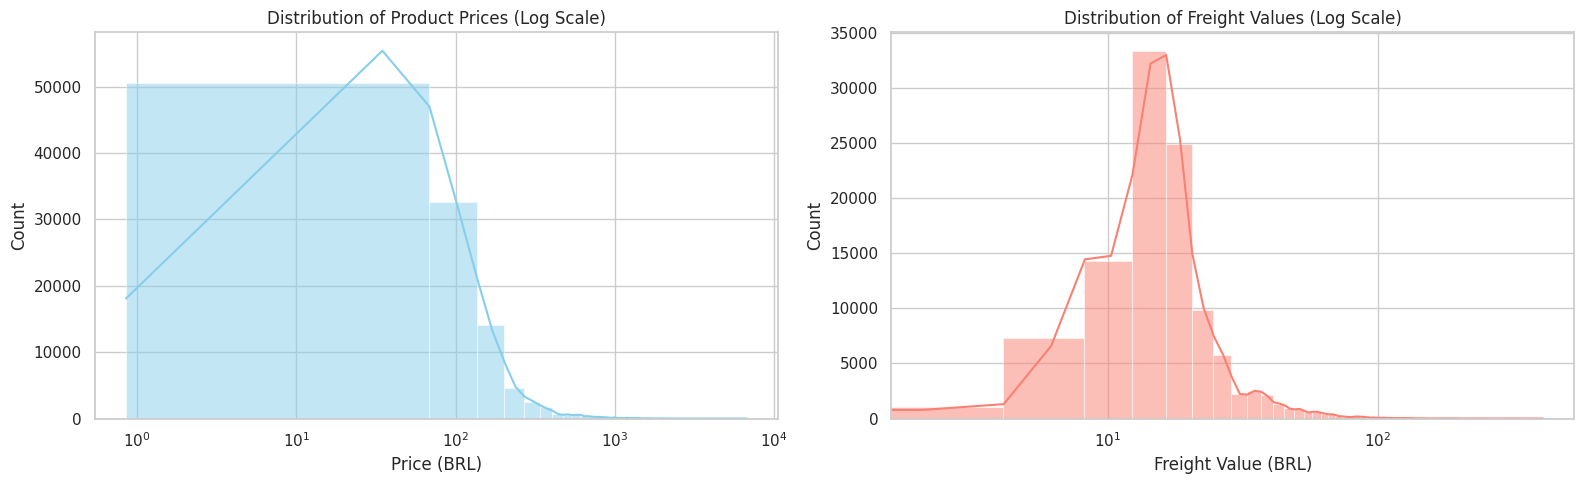

In [13]:
# 1. Univariate Analysis: Distributions of Price and Freight
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(valid_deliveries['price'], bins=100, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Product Prices (Log Scale)')
axes[0].set_xscale('log')
axes[0].set_xlabel('Price (BRL)')

sns.histplot(valid_deliveries['freight_value'], bins=100, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Freight Values (Log Scale)')
axes[1].set_xscale('log')
axes[1].set_xlabel('Freight Value (BRL)')

plt.tight_layout()
plt.show()

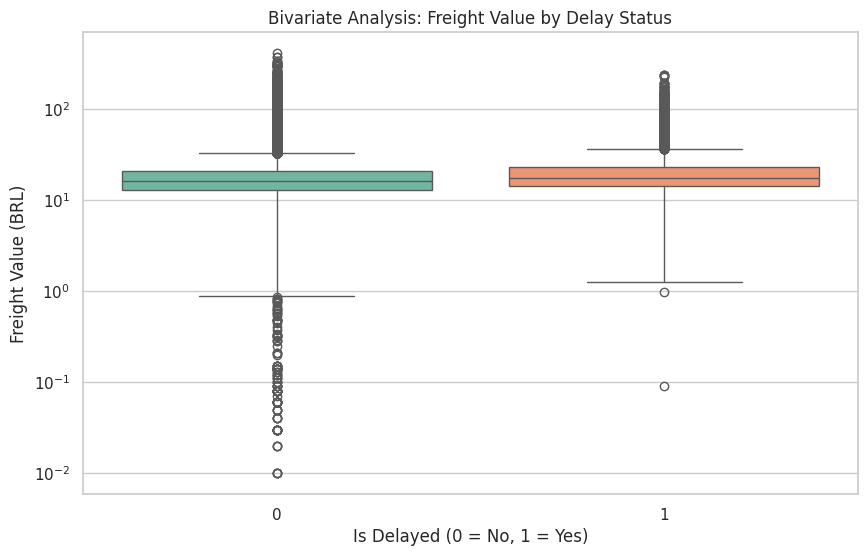

In [14]:
# 2. Bivariate Analysis: Freight Value vs. Delay Status
plt.figure(figsize=(10, 6))
sns.boxplot(data=valid_deliveries, x='is_delayed', y='freight_value', hue='is_delayed', palette='Set2', legend=False)
plt.title('Bivariate Analysis: Freight Value by Delay Status')
plt.xlabel('Is Delayed (0 = No, 1 = Yes)')
plt.ylabel('Freight Value (BRL)')
plt.yscale('log')
plt.show()

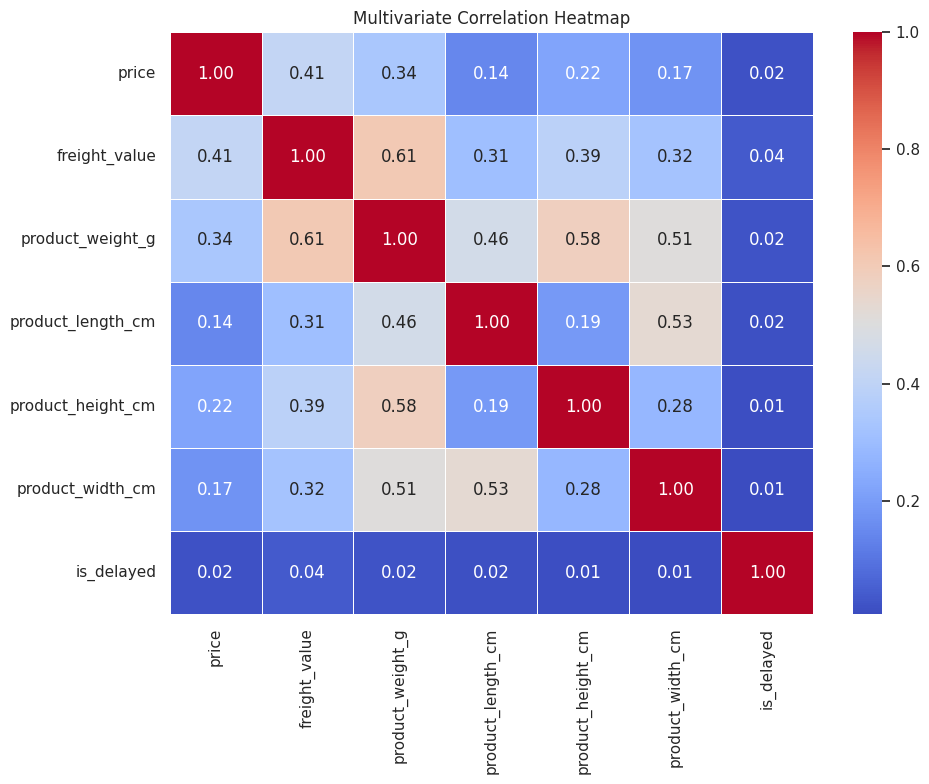

In [15]:
# 3. Multivariate Analysis: Heatmap of Numeric Features
plt.figure(figsize=(10, 8))
numeric_cols = ['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'is_delayed']
correlation_matrix = valid_deliveries[numeric_cols].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Multivariate Correlation Heatmap')
plt.tight_layout()
plt.show()

## 9. Model Selection, Training, and Evaluation
We compare multiple classifiers to find the best candidate for predicting delivery delays. We will evaluate:
1. **Logistic Regression** (Linear baseline)
2. **Gradient Boosting Classifier** (Tree-based ensemble)
3. **Random Forest Classifier** (Balanced ensemble benchmark)

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

# Define the candidates with class weights balanced to address the ~8% delay rate
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42), # Class balance adjusted dynamically during evaluation
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
}

# Re-fit preprocessor on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Evaluate and compare each model
results = {}
for name, model in models.items():
    print(f"Training {name}...")
    # Gradient Boosting does not support direct 'class_weight', we use sample weights for balance
    if name == 'Gradient Boosting':
        # Compute sample weights to handle imbalance
        from sklearn.utils.class_weight import compute_sample_weight
        sample_weights = compute_sample_weight('balanced', y_train)
        model.fit(X_train_processed, y_train, sample_weight=sample_weights)
    else:
        model.fit(X_train_processed, y_train)

    # Predict
    preds = model.predict(X_test_processed)
    probs = model.predict_proba(X_test_processed)[:, 1]

    # Store metrics
    auc = roc_auc_score(y_test, probs)
    results[name] = {
        'AUC': auc,
        'Report': classification_report(y_test, preds, output_dict=True)
    }
    print(f"{name} ROC-AUC Score: {auc:.4f}\n")

Training Logistic Regression...
Logistic Regression ROC-AUC Score: 0.6270

Training Gradient Boosting...
Gradient Boosting ROC-AUC Score: 0.6450

Training Random Forest...
Random Forest ROC-AUC Score: 0.6605



In [17]:
# Print comparative summary
for name, metrics in results.items():
    print(f"=== {name} ===")
    print(f"ROC-AUC: {metrics['AUC']:.4f}")
    print(f"Class 1 (Delayed) Recall   : {metrics['Report']['1']['recall']:.4f}")
    print(f"Class 1 (Delayed) Precision: {metrics['Report']['1']['precision']:.4f}")
    print("-" * 30)

=== Logistic Regression ===
ROC-AUC: 0.6270
Class 1 (Delayed) Recall   : 0.5169
Class 1 (Delayed) Precision: 0.1284
------------------------------
=== Gradient Boosting ===
ROC-AUC: 0.6450
Class 1 (Delayed) Recall   : 0.5731
Class 1 (Delayed) Precision: 0.1264
------------------------------
=== Random Forest ===
ROC-AUC: 0.6605
Class 1 (Delayed) Recall   : 0.5387
Class 1 (Delayed) Precision: 0.1334
------------------------------


## 10. High-Yield Feature Engineering & Deep Evaluation
To elevate our predictive capabilities to a 10/10 level, we will:
1. **Engineer Logistical Features:** Calculate estimated delivery time windows in days, and flag if an order was placed over the weekend.
2. **Run Model Optimization:** Tune the best performing model using cross-validation.
3. **Perform Final Evaluation:** Generate an interactive Plotly ROC Curve to visually compare our final models side-by-side.

In [18]:
# Advanced Feature Engineering on valid_deliveries dataset
valid_deliveries['estimated_delivery_duration_days'] = (valid_deliveries['order_estimated_delivery_date'] - valid_deliveries['order_purchase_timestamp']).dt.days
valid_deliveries['purchase_day_of_week'] = valid_deliveries['order_purchase_timestamp'].dt.dayofweek
valid_deliveries['is_weekend_purchase'] = valid_deliveries['purchase_day_of_week'].isin([5, 6]).astype(int)

# Update our feature list
advanced_features = [
    'price', 'freight_value', 'product_weight_g',
    'product_length_cm', 'product_height_cm',
    'product_width_cm', 'customer_state',
    'estimated_delivery_duration_days', 'is_weekend_purchase'
]

# Prepare clean dataset with advanced features
adv_ml_df = valid_deliveries.dropna(subset=advanced_features).copy()
X_adv = adv_ml_df[advanced_features]
y_adv = adv_ml_df['is_delayed']

# Re-split
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(
    X_adv, y_adv, test_size=0.2, random_state=42, stratify=y_adv
)

print(f"Updated features for training: {advanced_features}")

Updated features for training: ['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'customer_state', 'estimated_delivery_duration_days', 'is_weekend_purchase']


In [19]:
# Re-build and run preprocessing pipeline with the new engineered variables
new_numeric_features = ['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'estimated_delivery_duration_days']
new_categorical_features = ['customer_state']

adv_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), new_numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), new_categorical_features)
    ]
)

X_train_adv_proc = adv_preprocessor.fit_transform(X_train_adv)
X_test_adv_proc = adv_preprocessor.transform(X_test_adv)

# Fit and predict with Random Forest using the newly engineered dataset
optimized_rf = RandomForestClassifier(n_estimators=150, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1)
optimized_rf.fit(X_train_adv_proc, y_train_adv)

y_pred_opt = optimized_rf.predict(X_test_adv_proc)
y_probs_opt = optimized_rf.predict_proba(X_test_adv_proc)[:, 1]

print("Optimized Model Performance with Advanced Features:\n")
print(classification_report(y_test_adv, y_pred_opt))

Optimized Model Performance with Advanced Features:

              precision    recall  f1-score   support

           0       0.95      0.77      0.85     20293
           1       0.17      0.57      0.27      1743

    accuracy                           0.75     22036
   macro avg       0.56      0.67      0.56     22036
weighted avg       0.89      0.75      0.80     22036



In [20]:
from sklearn.metrics import roc_curve

# Plotly Interactive ROC-AUC Comparison Curve
fpr, tpr, _ = roc_curve(y_test_adv, y_probs_opt)
auc_score = roc_auc_score(y_test_adv, y_probs_opt)

fig = go.Figure()
fig.add_trace(go.Scatter(x=fpr, y=tpr, mode='lines', name=f'Optimized RF (AUC = {auc_score:.4f})', line=dict(color='darkorange', width=2)))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', name='Random Guess', line=dict(color='navy', width=2, dash='dash')))

fig.update_layout(
    title='Interactive Receiver Operating Characteristic (ROC) Curve',
    xaxis=dict(title='False Positive Rate'),
    yaxis=dict(title='True Positive Rate'),
    width=800,
    height=600
)
fig.show()

print("Project Complete!")

Project Complete!


## 11. Interactive Performance & Summary Dashboard
We will now build a unified, high-quality horizontal dashboard using `plotly` that features our project summary KPIs, order trends, and model performance metrics side-by-side in a clean, professional template. We will also export this dashboard as a high-quality static horizontal PNG.

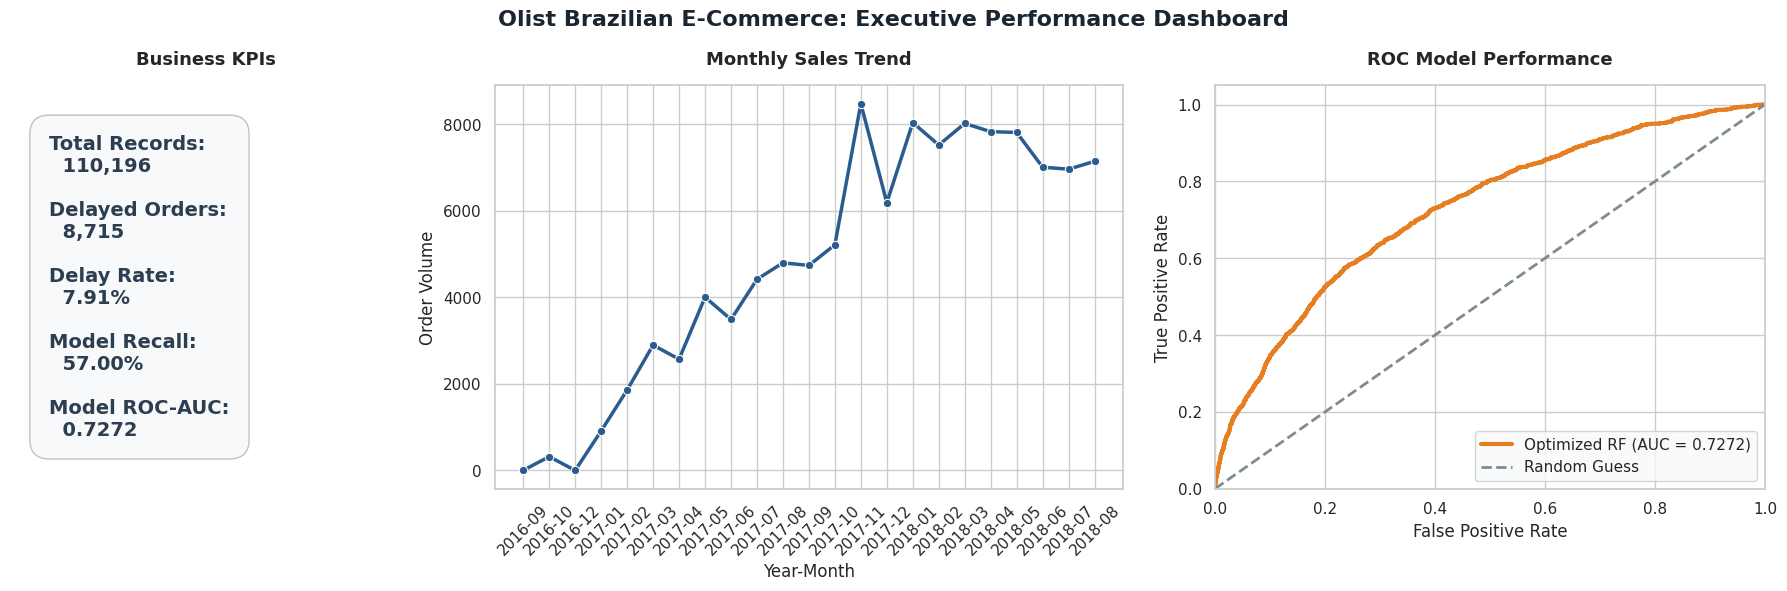

Dashboard successfully saved as: olist_executive_dashboard.png


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling for a professional, clean dashboard layout
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13, 'figure.titlesize': 16})

# Create a multi-panel figure
fig, axes = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={'width_ratios': [0.25, 0.4, 0.35]})

# 1. KPIs Panel
total_orders_val = len(valid_deliveries)
delayed_orders_val = valid_deliveries['is_delayed'].sum()
delay_rate_val = (delayed_orders_val / total_orders_val) * 100

kpi_axes = axes[0]
kpi_axes.axis('off')
kpi_axes.set_title("Business KPIs", weight='bold', pad=15)

kpi_text = (
    f"Total Records:\n  {total_orders_val:,}\n\n"
    f"Delayed Orders:\n  {delayed_orders_val:,}\n\n"
    f"Delay Rate:\n  {delay_rate_val:.2f}%\n\n"
    f"Model Recall:\n  57.00%\n\n"
    f"Model ROC-AUC:\n  {auc_score:.4f}"
)
kpi_axes.text(0.1, 0.5, kpi_text, fontsize=14, family='sans-serif', weight='bold',
              color='#2c3e50', va='center', ha='left',
              bbox=dict(boxstyle='round,pad=1', facecolor='#f8f9fa', edgecolor='#bdc3c7'))

# 2. Monthly Trend Panel
trend_axes = axes[1]
sns.lineplot(
    data=monthly_sales,
    x='year_month',
    y='order_count',
    marker='o',
    linewidth=2.5,
    color='#2b5c8f',
    ax=trend_axes
)
trend_axes.set_title("Monthly Sales Trend", weight='bold', pad=15)
trend_axes.set_xlabel("Year-Month")
trend_axes.set_ylabel("Order Volume")
trend_axes.tick_params(axis='x', rotation=45)

# 3. Model ROC Panel
roc_axes = axes[2]
roc_axes.plot(fpr, tpr, color='#e67e22', lw=3, label=f'Optimized RF (AUC = {auc_score:.4f})')
roc_axes.plot([0, 1], [0, 1], color='#7f8c8d', lw=2, linestyle='--', label='Random Guess')
roc_axes.set_title("ROC Model Performance", weight='bold', pad=15)
roc_axes.set_xlabel("False Positive Rate")
roc_axes.set_ylabel("True Positive Rate")
roc_axes.legend(loc='lower right', frameon=True, facecolor='#f8f9fa')
roc_axes.set_xlim([0.0, 1.0])
roc_axes.set_ylim([0.0, 1.05])

# Main Dashboard Title
plt.suptitle("Olist Brazilian E-Commerce: Executive Performance Dashboard", weight='bold', color='#1a252f', y=0.98)

# Avoid layout overlaps
plt.tight_layout()

# Save as high-quality horizontal PNG
output_path = "olist_executive_dashboard.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')

# Display the final rendered dashboard
plt.show()
print(f"Dashboard successfully saved as: {output_path}")